File Description

In [ ]:
# ==========================================================
# File Description
# ==========================================================
# File Name          : no_show_prediction.ipynb
# Author             : Habiba Ezat Abdeltawab
# Date of Creation   : 07-07-2026
# Version            : 1.0.0
# Dependencies       : numpy, pandas, scikit-learn, matplotlib,
#                      seaborn, lightgbm, xgboost, catboost
# Last Modified      : Habiba Ezat - 15-07-2026 03:30
# Description        : Medical appointment no-show prediction
#                      system using an optimized LightGBM model
#                      with class weights balancing.
# ==========================================================

Import Libraries

In [2]:
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from catboost import CatBoostClassifier
from imblearn.over_sampling import RandomOverSampler, SMOTE
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    train_test_split,
    validation_curve,
)
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

Constants Variables

In [3]:
RANDOM_STATE = 42
N_ESTIMATORS = 100
LEARNING_RATE = 0.1
CV = 5
N_JOBS = -1

Load Dataset

In [4]:
dataset_path = (r"KaggleV2-May-2016.csv")
df = pd.read_csv(dataset_path)

Show Data

In [5]:
# Show the first 5 rows of the dataset
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [6]:
# Show the last 5 rows of the dataset
df.tail()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
110522,2.572134e+12,5651768,F,2016-05-03T09:15:35Z,2016-06-07T00:00:00Z,56,MARIA ORTIZ,0,0,0,0,0,1,No
110523,3.596266e+12,5650093,F,2016-05-03T07:27:33Z,2016-06-07T00:00:00Z,51,MARIA ORTIZ,0,0,0,0,0,1,No
110524,1.557663e+13,5630692,F,2016-04-27T16:03:52Z,2016-06-07T00:00:00Z,21,MARIA ORTIZ,0,0,0,0,0,1,No
110525,9.213493e+13,5630323,F,2016-04-27T15:09:23Z,2016-06-07T00:00:00Z,38,MARIA ORTIZ,0,0,0,0,0,1,No
110526,3.775115e+14,5629448,F,2016-04-27T13:30:56Z,2016-06-07T00:00:00Z,54,MARIA ORTIZ,0,0,0,0,0,1,No


In [7]:
# Display the dataset dimensions 
df.shape

(110527, 14)

In [8]:
# Show the number of unique values in each column of the dataset 
df.nunique()

PatientId          62299
AppointmentID     110527
Gender                 2
ScheduledDay      103549
AppointmentDay        27
Age                  104
Neighbourhood         81
Scholarship            2
Hipertension           2
Diabetes               2
Alcoholism             2
Handcap                5
SMS_received           2
No-show                2
dtype: int64

In [9]:
# Show the summary statistics of the dataset
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PatientId,110527.0,1.474963e+14,2.560949e+14,3.921784e+04,4.172614e+12,3.173184e+13,9.439172e+13,9.999816e+14
AppointmentID,110527.0,5.675305e+06,7.129575e+04,5.030230e+06,5.640286e+06,5.680573e+06,5.725524e+06,5.790484e+06
Age,110527.0,3.708887e+01,2.311020e+01,-1.000000e+00,1.800000e+01,3.700000e+01,5.500000e+01,1.150000e+02
Scholarship,110527.0,9.826558e-02,2.976748e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Hipertension,110527.0,1.972459e-01,3.979213e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Diabetes,110527.0,7.186479e-02,2.582651e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Alcoholism,110527.0,3.039981e-02,1.716856e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Handcap,110527.0,2.224796e-02,1.615427e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
SMS_received,110527.0,3.210256e-01,4.668727e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00


In [10]:
# Show the column names 
df.columns

Index(['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay',
       'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension',
       'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show'],
      dtype='object')

In [11]:
# Show the information about the dataset, including data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


In [12]:
# Show the distribution of the target variable 'No-show'
df['No-show'].value_counts()

No-show
No     88208
Yes    22319
Name: count, dtype: int64

Data Cleaning

Check For Missing Values

In [13]:
df.isnull().sum()

PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

Check for Duplicated Values

In [14]:
df.duplicated().sum()

np.int64(0)

Check For Logical Error

In [15]:
# count records with invalid age values 
(df['Age']<=0).sum()

np.int64(3540)

In [16]:
# Display age distribution 
df['Age'].value_counts().sort_index().head(10)

Age
-1       1
 0    3539
 1    2273
 2    1618
 3    1513
 4    1299
 5    1489
 6    1521
 7    1427
 8    1424
Name: count, dtype: int64

Handle Logical Error

In [17]:
# Remove rows with negative values in the 'Age' column
df=df[df['Age']>=0]

Detect Outliers in Age

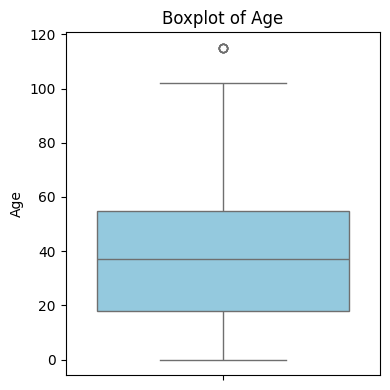

In [18]:
plt.figure(figsize=(4,4))
sns.boxplot(y=df['Age'], color="skyblue")
plt.title("Boxplot of Age")
plt.tight_layout()
plt.show()

Exploratory Data Analysis (EDA)

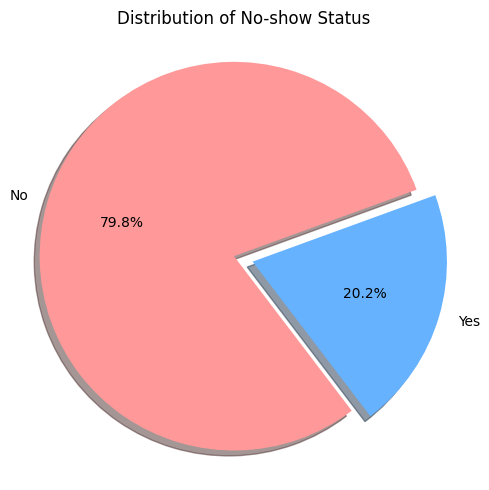

In [19]:
# Display the distribution of the target variable 'No-show' using a pie chart
colors = ["#FF9999", "#66B2FF"]
explode = (0.1, 0)  
plt.figure(figsize=(5,5))
plt.pie(
    df['No-show'].value_counts(),
    labels=df['No-show'].value_counts().index,
    autopct='%1.1f%%',
    colors=colors,
    shadow=True,
    startangle=20,
    explode=explode
)

plt.title("Distribution of No-show Status")
plt.axis('equal')
plt.tight_layout()
plt.show()

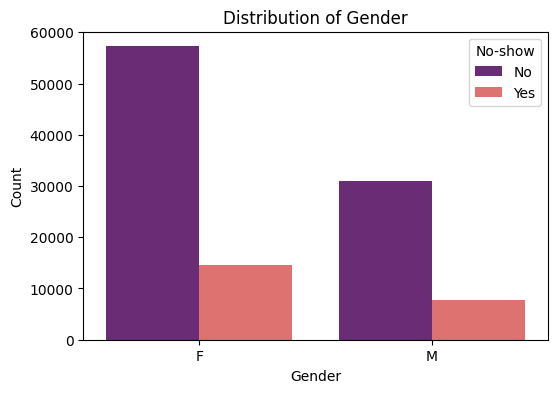

In [20]:
# Gender distribution by No-show status
plt.figure(figsize=(6,4))
sns.countplot(x='Gender', data=df, palette='magma', hue='No-show')
plt.title('Distribution of Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

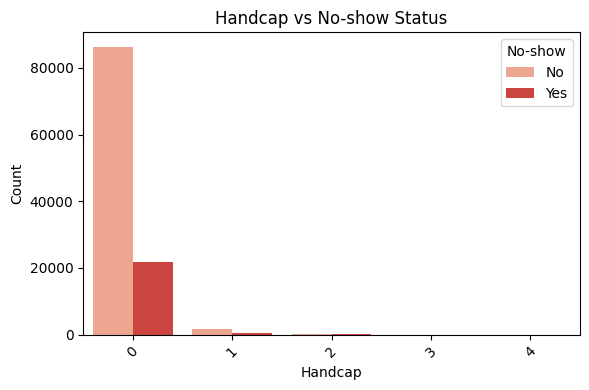

In [21]:
# Handcap distribution by No-show status
plt.figure(figsize=(6,4))
sns.countplot(x='Handcap', data=df, hue='No-show', palette='Reds')
plt.title('Handcap vs No-show Status')
plt.xlabel('Handcap')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='No-show')
plt.tight_layout()
plt.show()

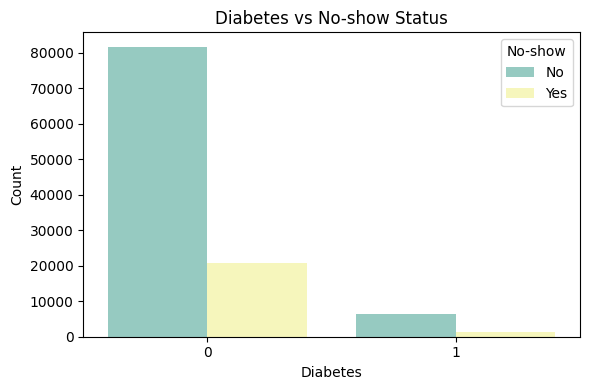

In [22]:
# Diabetes distribution by No-show status
plt.figure(figsize=(6,4))
sns.countplot(x='Diabetes', data=df, hue='No-show', palette='Set3')
plt.title('Diabetes vs No-show Status')
plt.xlabel('Diabetes')
plt.ylabel('Count')
plt.legend(title='No-show')
plt.tight_layout()
plt.show()

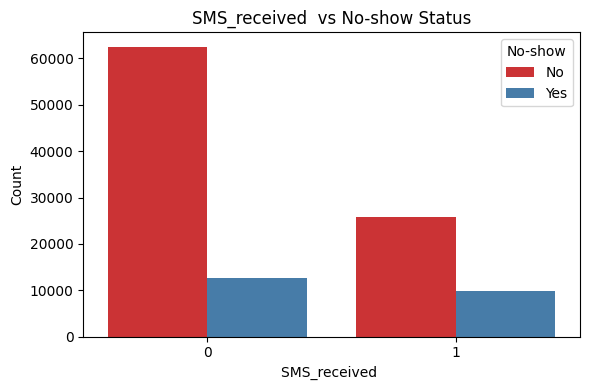

In [23]:
# SMS_received distribution by No-show status
plt.figure(figsize=(6,4))
sns.countplot(x='SMS_received', data=df, hue='No-show', palette='Set1')
plt.title('SMS_received  vs No-show Status')
plt.xlabel('SMS_received ')
plt.ylabel('Count')
plt.legend(title='No-show')
plt.tight_layout()
plt.show()

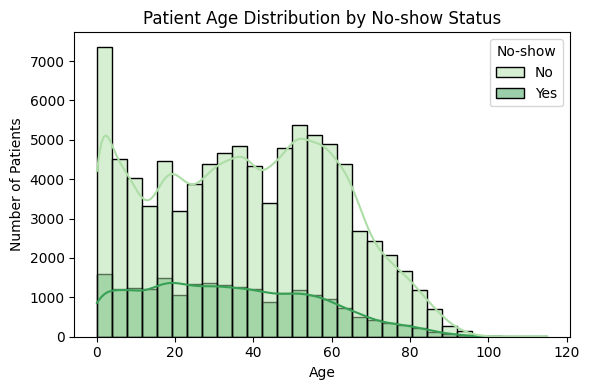

In [24]:
# Age distribution by No-show status
plt.figure(figsize=(6,4))
sns.histplot(data=df, x='Age', hue='No-show', bins=30, kde=True, palette='Greens')
plt.title("Patient Age Distribution by No-show Status")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

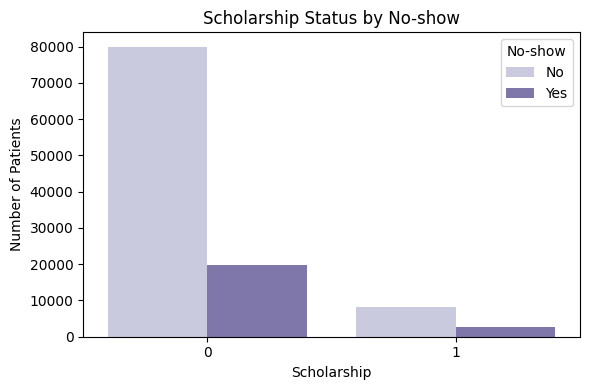

In [25]:
# Scholarship distribution by No-show status
plt.figure(figsize=(6,4))
sns.countplot(x='Scholarship', hue='No-show', data=df, palette='Purples')
plt.title("Scholarship Status by No-show")
plt.xlabel("Scholarship")
plt.ylabel("Number of Patients")
plt.legend(title="No-show")
plt.tight_layout()
plt.show()

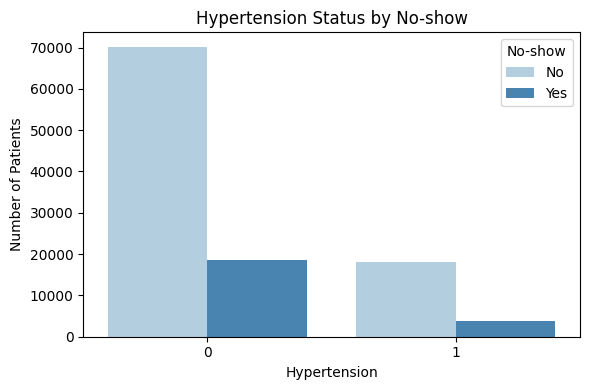

In [26]:
# Hypertension distribution by No-show status
plt.figure(figsize=(6,4))
sns.countplot(x='Hipertension', hue='No-show', data=df, palette='Blues')
plt.title("Hypertension Status by No-show")
plt.xlabel("Hypertension")
plt.ylabel("Number of Patients")
plt.legend(title="No-show")
plt.tight_layout()
plt.show()

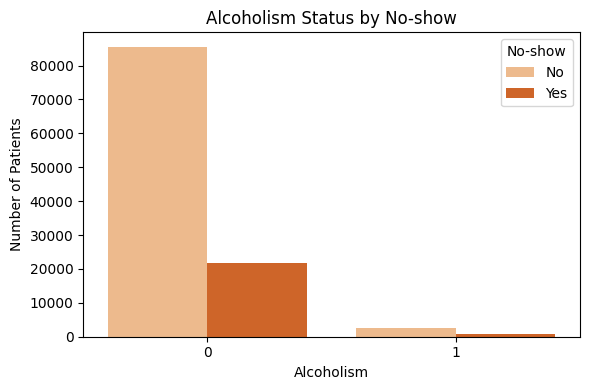

In [27]:
# Alcoholism distribution by No-show status
plt.figure(figsize=(6,4))
sns.countplot(x='Alcoholism', hue='No-show', data=df, palette='Oranges')
plt.title("Alcoholism Status by No-show")
plt.xlabel("Alcoholism")
plt.ylabel("Number of Patients")
plt.legend(title="No-show")
plt.tight_layout()
plt.show()

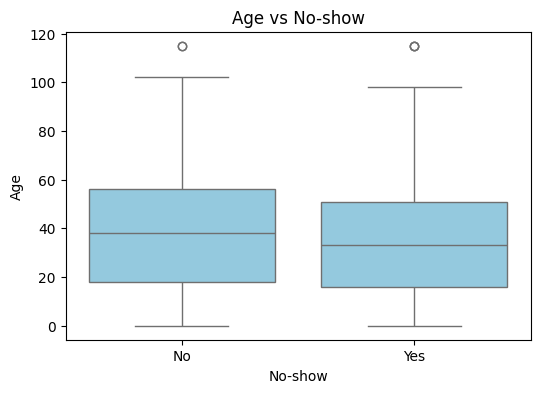

In [28]:
# Age vs No-show distribution
plt.figure(figsize=(6,4))
sns.boxplot(x='No-show', y='Age', color='skyblue', data=df)
plt.title("Age vs No-show")
plt.show()

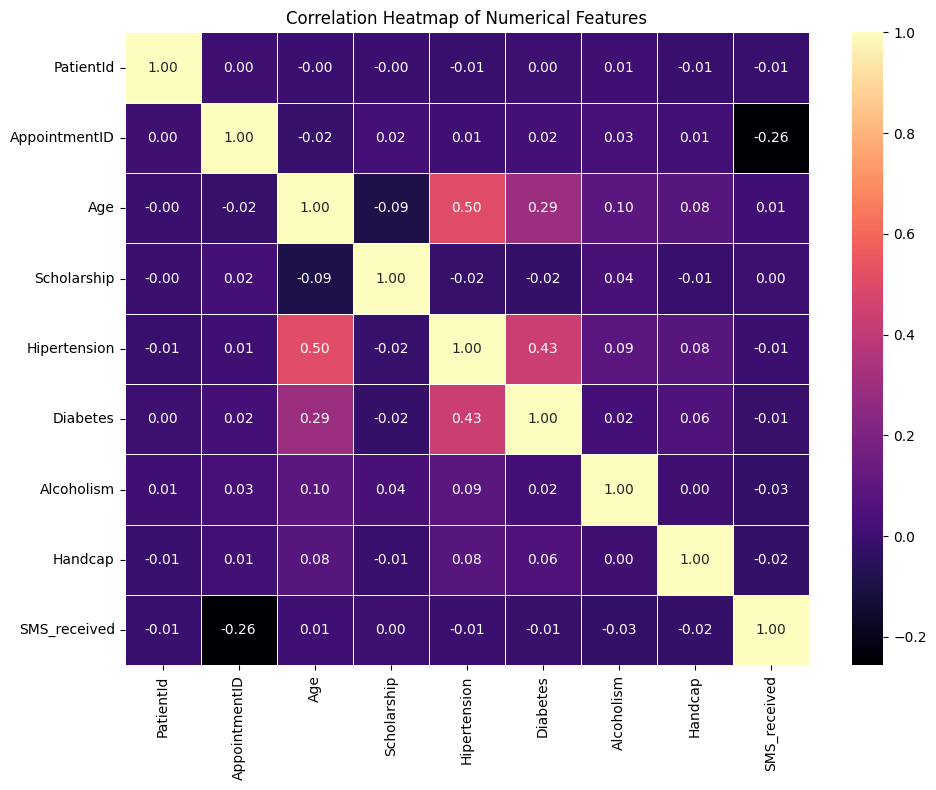

In [29]:
# Correlation heatmap of numerical features
plt.figure(figsize=(10,8))
numeric_df = df.select_dtypes(include=['int64', 'float64'])
sns.heatmap( numeric_df.corr(), annot=True, cmap='magma', fmt='.2f', linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

Feature Engineering

In [30]:
# Convert date columns from object to datetime format
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])
print(df[['ScheduledDay', 'AppointmentDay']].dtypes)

ScheduledDay      datetime64[ns, UTC]
AppointmentDay    datetime64[ns, UTC]
dtype: object


In [31]:
# ==========================================================
# Feature: WaitingDays
# Calculate the number of waiting days between the appointment booking date and the appointment date.
# Time information is removed before calculation.
# ==========================================================
df['WaitingDays'] = (df['AppointmentDay'].dt.normalize() - df['ScheduledDay'].dt.normalize()).dt.days

Check For Logical Error in WaitingDays

In [32]:
# Show the summary statistics of the 'WaitingDays' column
df['WaitingDays'].describe()


count    110526.000000
mean         10.183794
std          15.255034
min          -6.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
Name: WaitingDays, dtype: float64

In [33]:
# Check for negative values in the 'WaitingDays' column
(df['WaitingDays'] < 0).sum()

np.int64(5)

Remove Invalid Waiting Days

In [34]:
df = df[df['WaitingDays'] >= 0]

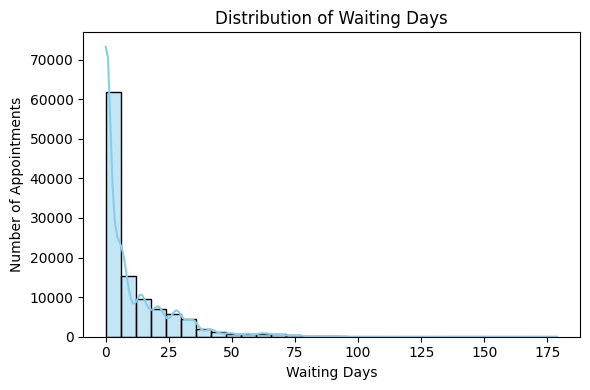

In [35]:
# Waiting days distribution
plt.figure(figsize=(6,4))
sns.histplot(df['WaitingDays'], bins=30, kde=True, color='skyblue')
plt.title("Distribution of Waiting Days")
plt.xlabel("Waiting Days")
plt.ylabel("Number of Appointments")
plt.tight_layout()
plt.show()

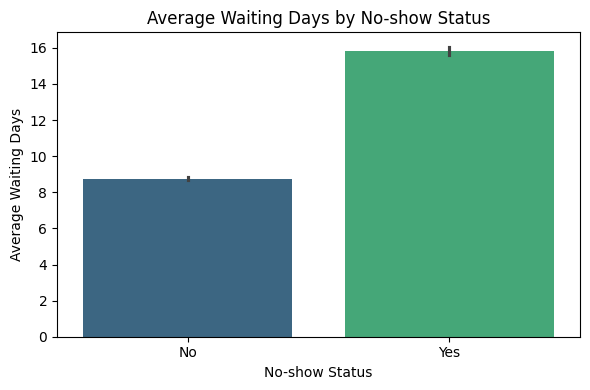

In [36]:
# Average waiting days by No-show status
plt.figure(figsize=(6,4))
sns.barplot(x='No-show', y='WaitingDays', data=df, estimator='mean', palette='viridis')
plt.title("Average Waiting Days by No-show Status")
plt.xlabel("No-show Status")
plt.ylabel("Average Waiting Days")
plt.tight_layout()
plt.show()

In [37]:
# ==========================================================
# Feature: AppointmentWeekday
# Extract the day of the week on which the appointment takes place. 
# Patients may behave differently depending on the appointment day.
# ==========================================================
df['AppointmentWeekday'] = df['AppointmentDay'].dt.day_name()

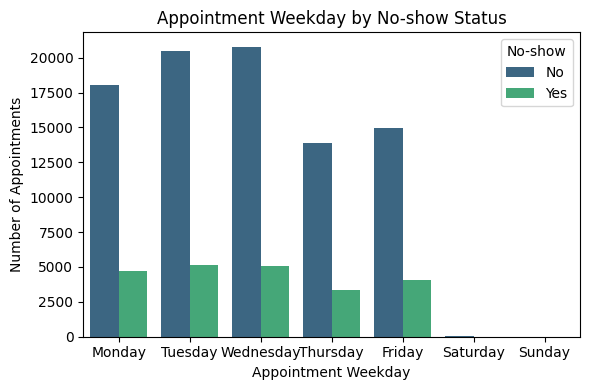

In [38]:
# Show the distribution of appointments across weekdays
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday','Friday', 'Saturday', 'Sunday']
plt.figure(figsize=(6,4))
sns.countplot( x='AppointmentWeekday', hue='No-show', data=df, order=weekday_order, palette='viridis')
plt.title("Appointment Weekday by No-show Status")
plt.xlabel("Appointment Weekday")
plt.ylabel("Number of Appointments")
plt.legend(title="No-show")
plt.tight_layout()
plt.show()

In [39]:
# ==========================================================
# Feature: ScheduledWeekday
# Extract the day of the week when the appointment was booked.
# ==========================================================
df['ScheduledWeekday'] = df['ScheduledDay'].dt.day_name()

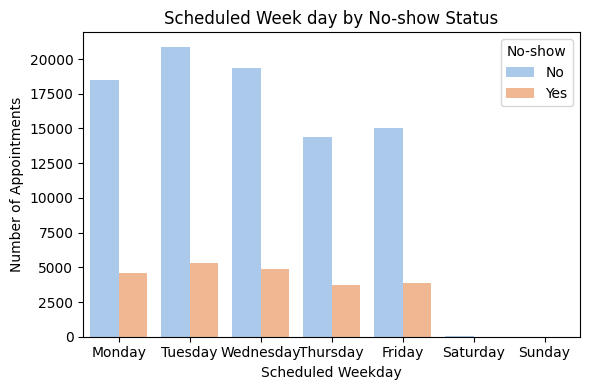

In [40]:
# Show the distribution of scheduled appointments across weekdays
plt.figure(figsize=(6,4))
sns.countplot( x='ScheduledWeekday', hue='No-show', data=df, order=weekday_order, palette='pastel')
plt.title("Scheduled Week day by No-show Status")
plt.xlabel("Scheduled Weekday")
plt.ylabel("Number of Appointments")
plt.legend(title="No-show")
plt.tight_layout()
plt.show()

In [41]:
# ==========================================================
# Feature: DiseaseCount
# Count the total number of chronic medical conditions for each patient.
# ==========================================================
df['DiseaseCount'] = (df['Hipertension']+ df['Diabetes']+ df['Alcoholism'])

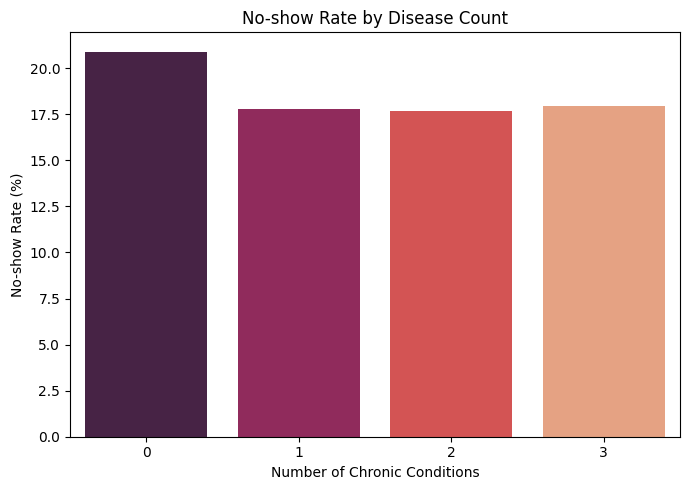

In [42]:
disease_rate = (df.groupby('DiseaseCount')['No-show'] .apply(lambda values: (values == 'Yes').mean() * 100))
plt.figure(figsize=(7,5))
sns.barplot(x=disease_rate.index, y=disease_rate.values, palette='rocket')
plt.title("No-show Rate by Disease Count")
plt.xlabel("Number of Chronic Conditions")
plt.ylabel("No-show Rate (%)")
plt.tight_layout()
plt.show()

Drop Unwanted Features

In [43]:
columns_to_drop = ['PatientId','AppointmentID','Neighbourhood','ScheduledDay','AppointmentDay']
df.drop(columns=columns_to_drop,inplace=True)

Data Preprocessing

Label Encoding For Target (No-show) and Gender 

In [44]:
gender_encoder = LabelEncoder()
df['Gender'] = gender_encoder.fit_transform(df['Gender'])

target_encoder = LabelEncoder()
df['No-show'] = target_encoder.fit_transform(df['No-show'])

One Hot Encoding For AppointmentWeekday and ScheduledWeekday

In [45]:
df = pd.get_dummies(df, columns=['AppointmentWeekday'], prefix='AppDay', dtype=int)
df = pd.get_dummies( df, columns=['ScheduledWeekday'], prefix='SchDay', dtype=int)

Correlation Heatmap After Features Engineering and Encoding

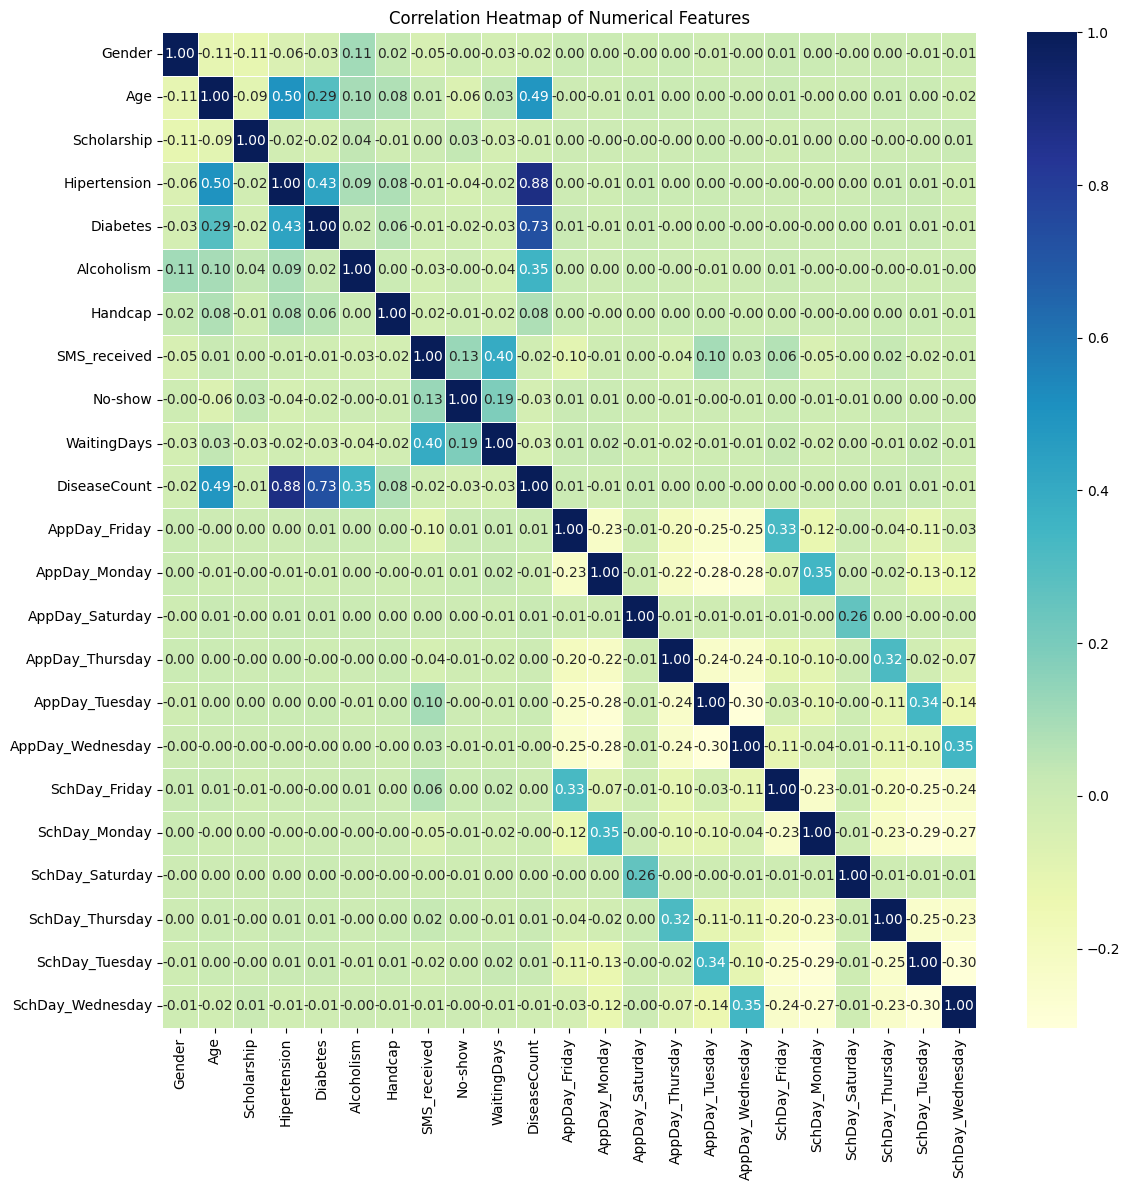

In [46]:
plt.figure(figsize=(12,12))
numeric_df = df.select_dtypes(include=np.number)
sns.heatmap( numeric_df.corr(), annot=True, cmap='YlGnBu', fmt='.2f', linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

Split Data

In [47]:
# Split the dataset into features and target 
features = df.drop(columns=['No-show'], axis=1)
target = df['No-show']

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    features, 
    target, 
    test_size=0.2, 
    random_state=RANDOM_STATE, 
    stratify=target
    )   

 Hyperparameter Tuning Functions

In [49]:
# Function: Calculate Mean Scores

def calculate_mean_scores(train_scores, test_scores):
    """
    Calculate the mean training and validation scores.
    """

    train_mean = np.mean(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)

    return train_mean, test_mean

In [50]:
# Function: Plot Validation Curve

def plot_validation_curve(
    param_range,
    train_mean,
    test_mean,
    title,
    parameter_name,
):
    """
    Plot the training and validation accuracy curves.
    """

    plt.figure(figsize=(6, 4))

    plt.plot(
        param_range,
        train_mean,
        marker="o",
        linewidth=2,
        label="Training Accuracy",
    )

    plt.plot(
        param_range,
        test_mean,
        marker="o",
        linewidth=2,
        label="Cross Validation Accuracy",
    )

    plt.title(title)
    plt.xlabel(parameter_name)
    plt.ylabel("Accuracy")
    plt.legend(loc="best")
    plt.grid(True)

    plt.tight_layout()
    plt.show()

Random Forest

In [51]:
# ==========================================================
# Hyperparameter Tuning for Random Forest
# Tune the max_depth parameter using GridSearchCV
# ==========================================================
param_grid_rf = {'max_depth': [5, 10, 15, 20, 25]}

grid_rf = GridSearchCV (
    RandomForestClassifier(n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE),
    param_grid=param_grid_rf,
    cv=CV,
    scoring='accuracy',
    n_jobs=N_JOBS
)
grid_rf.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [5, 10, 15, 20, 25]}, scoring='accuracy')

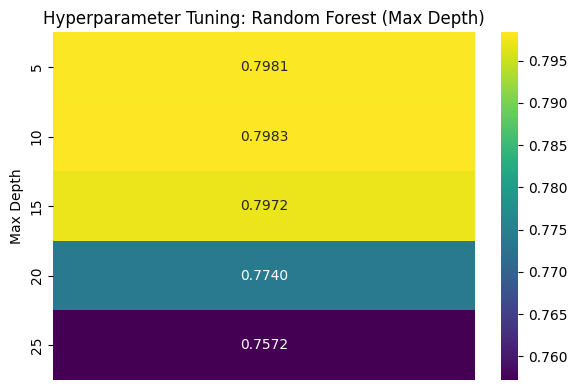

In [52]:
# Draw a heatmap to visualize the mean test scores for different max_depth values   
plt.figure(figsize=(6,4))
scores_rf = grid_rf.cv_results_['mean_test_score'].reshape(-1,1)

sns.heatmap( 
    scores_rf, 
    annot=True, 
    fmt=".4f",
    xticklabels=[], 
    yticklabels=param_grid_rf['max_depth'],
    cmap='viridis'
    )

plt.title("Hyperparameter Tuning: Random Forest (Max Depth)")
plt.ylabel("Max Depth")
plt.tight_layout()
plt.show()

In [53]:
# Print the best parameters and best cross-validation accuracy
print("Best Parameters :", grid_rf.best_params_)
print("Best CV Accuracy:", grid_rf.best_score_)

Best Parameters : {'max_depth': 10}
Best CV Accuracy: 0.7983396694837223


XGBoost

In [54]:
# ==========================================================
# Hyperparameter Tuning for XGBoost
# Tune the max_depth parameter using Validation Curve
# ==========================================================
param_range = [3, 4, 5, 6, 8, 10]
train_scores, test_scores = validation_curve(
    XGBClassifier(n_estimators=N_ESTIMATORS, 
                  learning_rate=LEARNING_RATE, 
                  random_state=RANDOM_STATE, 
                  eval_metric='logloss'
                  ),
                  
                  X_train,
                  y_train,
                  param_name="max_depth",
                  param_range=param_range,
                  cv=CV,
                  scoring="accuracy",
                  n_jobs=N_JOBS
)

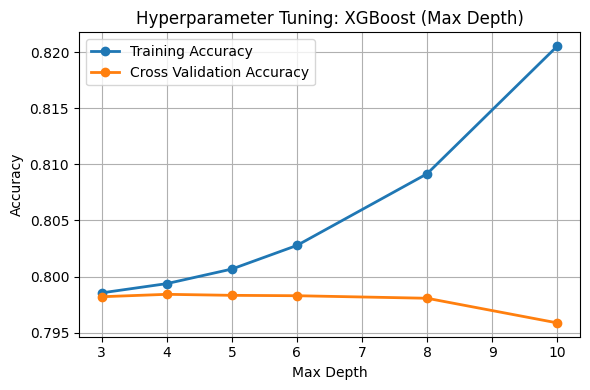

In [55]:
train_mean, test_mean = calculate_mean_scores(train_scores, test_scores)

plot_validation_curve(
    param_range=param_range,
    train_mean=train_mean,
    test_mean=test_mean,
    title="Hyperparameter Tuning: XGBoost (Max Depth)",
    parameter_name="Max Depth",
)

CatBoost

In [56]:
# ==========================================================
# Hyperparameter Tuning for CatBoost
# Tune the depth parameter using Validation Curve
# ==========================================================
param_range = [2, 4, 6, 8, 10]
train_scores, test_scores = validation_curve(
    CatBoostClassifier(
    iterations=N_ESTIMATORS, 
    learning_rate=LEARNING_RATE, 
    verbose=0, 
    random_seed=RANDOM_STATE
    ),
    X_train,
    y_train,
    param_name="depth", 
    param_range=param_range,
    cv=CV, 
    scoring="accuracy",
    n_jobs=N_JOBS
)

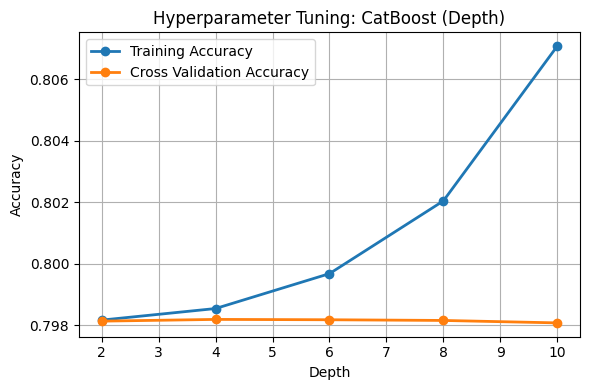

In [57]:
train_mean, test_mean = calculate_mean_scores(train_scores, test_scores)

plot_validation_curve(
    param_range=param_range,
    train_mean=train_mean,
    test_mean=test_mean,
    title="Hyperparameter Tuning: CatBoost (Depth)",
    parameter_name="Depth",
)

LightGBM

In [58]:
# ==========================================================
# Hyperparameter Tuning for LightGBM
# Tune the max_depth parameter using Validation Curve
# ==========================================================
param_range = [3, 4, 5, 6, 8, 10]
train_scores, test_scores = validation_curve(
    LGBMClassifier(n_estimators=N_ESTIMATORS, learning_rate=LEARNING_RATE, random_state=RANDOM_STATE),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=param_range,
    cv=CV,
    scoring="accuracy",
    n_jobs=N_JOBS
)

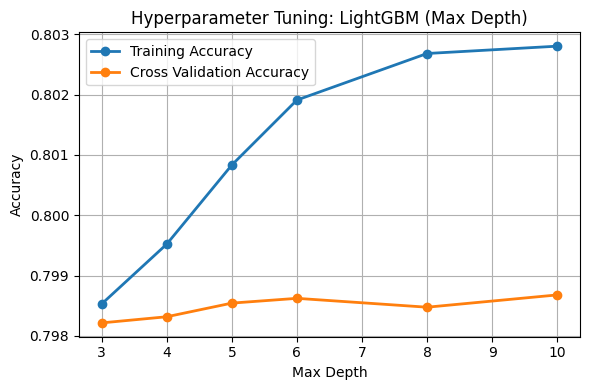

In [59]:
train_mean, test_mean = calculate_mean_scores(train_scores, test_scores)

plot_validation_curve(
    param_range=param_range,
    train_mean=train_mean,
    test_mean=test_mean,
    title="Hyperparameter Tuning: LightGBM (Max Depth)",
    parameter_name="Max Depth",
)

Model Training Before Feature Selection

In [60]:
# Train Random Forest Model
rf_model = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=10,random_state=RANDOM_STATE)
rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, random_state=42)

In [61]:
# Train XGBoost Model
xgb_model = XGBClassifier(
    n_estimators=N_ESTIMATORS, 
    max_depth=4, 
    learning_rate=LEARNING_RATE, 
    random_state=RANDOM_STATE, 
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [62]:
# Train CatBoost Model
cat_model = CatBoostClassifier(
    iterations=N_ESTIMATORS, 
    depth=6, 
    learning_rate=LEARNING_RATE, 
    verbose=0, 
    random_seed=RANDOM_STATE
)

cat_model.fit(X_train, y_train)

CatBoostClassifier(depth=6, iterations=100, learning_rate=0.1, random_seed=42, verbose=0)

In [63]:
# Train LightGBM Model
lgbm_model = LGBMClassifier(
    n_estimators=N_ESTIMATORS,
    max_depth=6,
    learning_rate=LEARNING_RATE,
    random_state=RANDOM_STATE,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)

LGBMClassifier(max_depth=6, random_state=42, verbosity=-1)

Model Evaluation Function

In [64]:
# ==========================================================
# Evaluate Multiple Classification Models
# This function evaluates trained models by calculating
# performance metrics, displaying classification reports,
# plotting confusion matrices, and returning the results
# as a DataFrame.
# ==========================================================

def evaluate_models(models, x_train_full, x_test_full, y_train, y_test, title, cmap, features_dict=None):
    evaluation_results = []
    plt.figure(figsize=(22, 5))

    for index, (name, model) in enumerate(models.items()):
        # Dynamically slice features if features_dict is provided (Post-RFE)
        if features_dict and name in features_dict:
            current_features = features_dict[name]
            x_train = x_train_full[current_features]
            x_test = x_test_full[current_features]
        else:
            x_train = x_train_full
            x_test = x_test_full
        # Calculate training and testing accuracy
        train_acc = model.score(x_train, y_train)
        test_acc = model.score(x_test, y_test)

        # Generate predictions on the test dataset
        y_pred = model.predict(x_test)

         # Calculate classification evaluation metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        
        # Save the evaluation metrics for later comparison
        evaluation_results.append([name, acc, prec, rec, f1])
        
        # Print the evaluation report for the current model
        print(f"\n{'=' * 60}\n{name} {title}\n{'=' * 60}")
        print(f"Training Accuracy : {train_acc:.4f}")
        print(f"Testing Accuracy  : {test_acc:.4f}")
        print("\nClassification Report:")
        print(classification_report(y_test, y_pred))

        # Create a subplot for the confusion matrix
        plt.subplot(1, 4, index + 1)

        # Compute the confusion matrix
        cm = confusion_matrix(y_test, y_pred)

        # Display the confusion matrix as a heatmap
        sns.heatmap(cm, 
                    annot=True, 
                    fmt="d", 
                    cmap=cmap, 
                    cbar=False,
                    xticklabels=["No Show", "Show"], 
                    yticklabels=["No Show", "Show"]
        )
        
        plt.title(f"Confusion Matrix\n{name}")
        plt.xlabel("Predicted Label")
        plt.ylabel("Actual Label")

    # Adjust the layout and display the figure
    plt.tight_layout()
    plt.show()
    
     # Return all evaluation metrics as a DataFrame
    return pd.DataFrame(
        evaluation_results, 
        columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score"]
    )

Baseline Evaluation


Random Forest Evaluation Report Original Data
Training Accuracy : 0.7991
Testing Accuracy  : 0.7983

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     17642
           1       0.69      0.00      0.00      4463

    accuracy                           0.80     22105
   macro avg       0.75      0.50      0.45     22105
weighted avg       0.78      0.80      0.71     22105


XGBoost Evaluation Report Original Data
Training Accuracy : 0.7989
Testing Accuracy  : 0.7983

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     17642
           1       0.55      0.01      0.01      4463

    accuracy                           0.80     22105
   macro avg       0.67      0.50      0.45     22105
weighted avg       0.75      0.80      0.71     22105


CatBoost Evaluation Report Original Data
Training Accuracy : 0.7992
Testing Accuracy  : 0.7982

Class

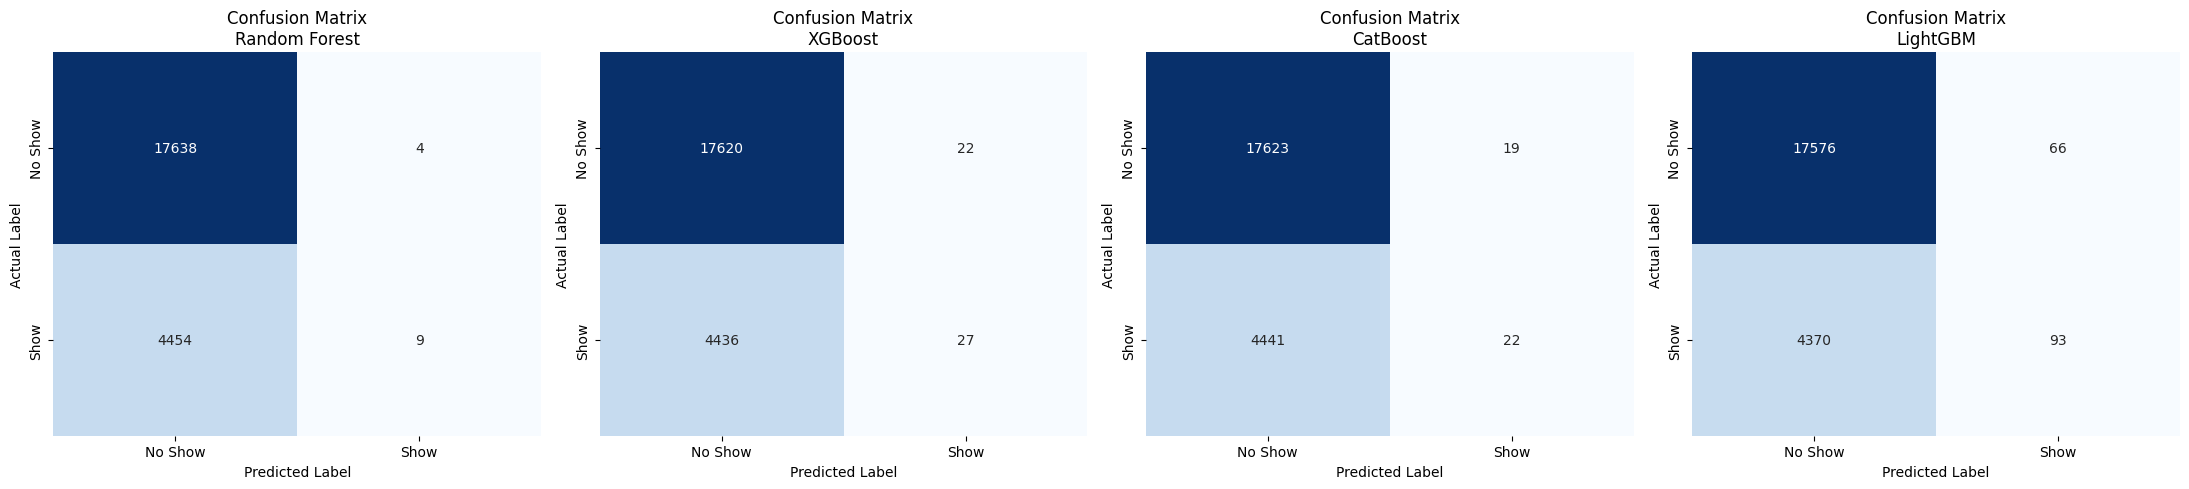

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.798326,0.692308,0.002017,0.004021
1,XGBoost,0.798326,0.551020,0.006050,0.011968
2,CatBoost,0.798236,0.536585,0.004929,0.009769
3,LightGBM,0.799321,0.584906,0.020838,0.040242


In [65]:

trained_models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "CatBoost": cat_model,
    "LightGBM": lgbm_model,
}

results_before_selection = evaluate_models(
    trained_models,
    X_train,
    X_test,
    y_train,
    y_test,
    "Evaluation Report Original Data",
    "Blues"
)

results_before_selection

Handle Imbalance Using Class Weights

RandomForest

In [66]:
rf_model_balanced = RandomForestClassifier(
    n_estimators=N_ESTIMATORS, 
    max_depth=10,
    random_state=RANDOM_STATE, 
    class_weight='balanced'
)

rf_model_balanced.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, random_state=42)

 XGBoost

In [67]:
# Calculate the class imbalance ratio for XGBoost
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(scale_pos_weight)

3.952999831942188


In [68]:
xgb_model_balanced = XGBClassifier(
    n_estimators=N_ESTIMATORS, 
    max_depth=4,
    learning_rate=LEARNING_RATE, 
    random_state=RANDOM_STATE, 
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight
)

xgb_model_balanced.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

CatBoost

In [69]:
class_weights = [1,(y_train == 0).sum() / (y_train == 1).sum()]
cat_model_balanced = CatBoostClassifier(
    iterations=N_ESTIMATORS, 
    depth=6, 
    learning_rate=LEARNING_RATE, 
    verbose=0, 
    random_seed=RANDOM_STATE, 
    class_weights=class_weights
)

cat_model_balanced.fit(X_train, y_train)

CatBoostClassifier(class_weights=[1, np.float64(3.952999831942188)], depth=6, iterations=100, learning_rate=0.1, random_seed=42, verbose=0)

LGBMClassifier

In [70]:
lgbm_model_balanced = LGBMClassifier(
    n_estimators=N_ESTIMATORS, 
    max_depth=6, 
    learning_rate=LEARNING_RATE, 
    random_state=RANDOM_STATE, 
    verbosity=-1, 
    class_weight='balanced'
)

lgbm_model_balanced.fit(X_train, y_train)

LGBMClassifier(class_weight='balanced', max_depth=6, random_state=42,
               verbosity=-1)

Model Evaluation After Class Weight Balanced


Random Forest Evaluation Report Balanced Data
Training Accuracy : 0.5965
Testing Accuracy  : 0.5746

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.51      0.66     17642
           1       0.30      0.83      0.44      4463

    accuracy                           0.57     22105
   macro avg       0.61      0.67      0.55     22105
weighted avg       0.80      0.57      0.61     22105


XGBoost Evaluation Report Balanced Data
Training Accuracy : 0.5925
Testing Accuracy  : 0.5834

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.52      0.67     17642
           1       0.30      0.83      0.44      4463

    accuracy                           0.58     22105
   macro avg       0.61      0.67      0.56     22105
weighted avg       0.80      0.58      0.62     22105


CatBoost Evaluation Report Balanced Data
Training Accuracy : 0.5951
Testing Accuracy  : 0.5851

Class

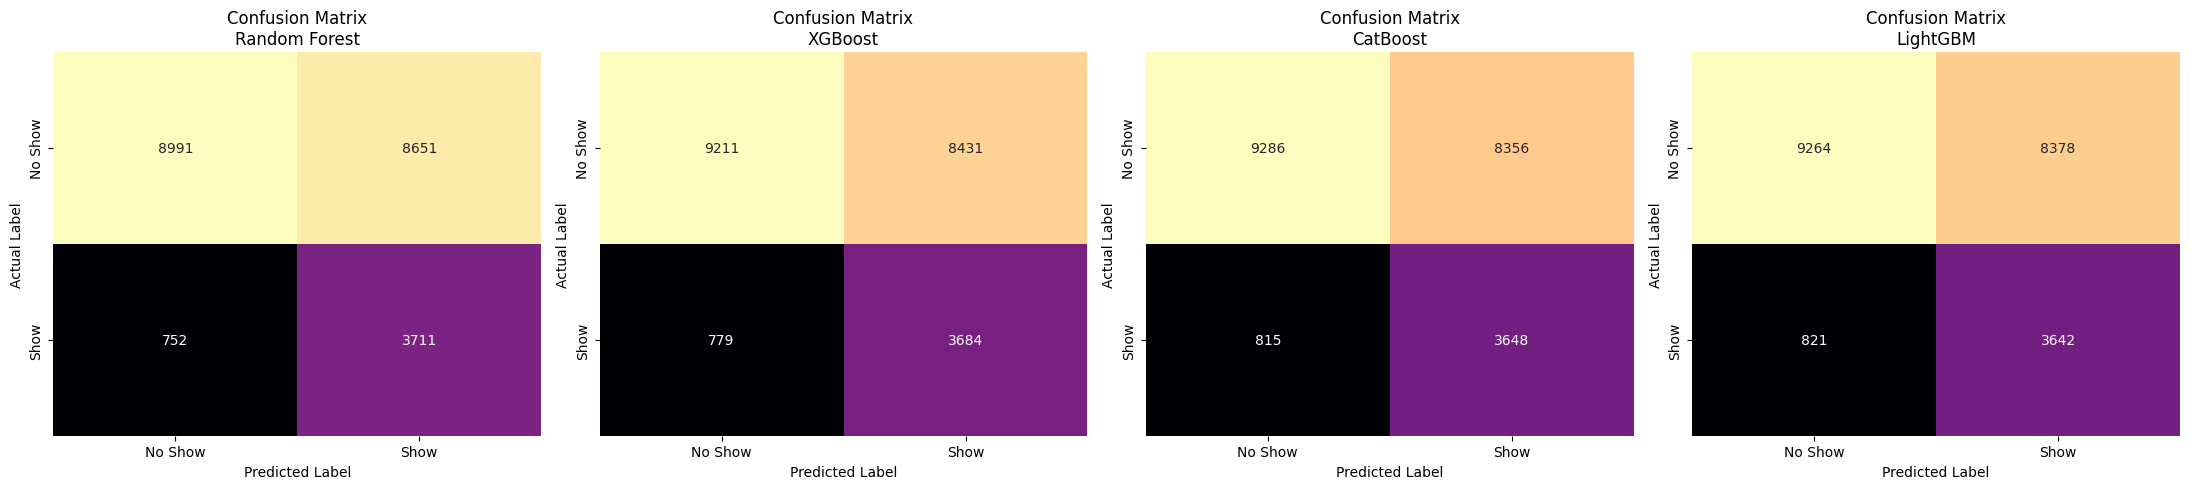

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.574621,0.300194,0.831503,0.441129
1,XGBoost,0.583352,0.304086,0.825454,0.444444
2,CatBoost,0.585116,0.303899,0.817387,0.443068
3,LightGBM,0.583850,0.302995,0.816043,0.441910


In [71]:
balanced_models = {
    "Random Forest": rf_model_balanced,
    "XGBoost": xgb_model_balanced,
    "CatBoost": cat_model_balanced,
    "LightGBM": lgbm_model_balanced,
}
results_class_weights = evaluate_models(
    balanced_models,
    X_train,
    X_test,
    y_train,
    y_test,
    "Evaluation Report Balanced Data",
    "magma"
)

results_class_weights

Features Selection

In [72]:
sample_weights= compute_sample_weight(class_weight='balanced', y=y_train)

In [73]:
# Feature Selection Using Recursive Feature Elimination (RFE)
rfe_estimators = {
    "Random Forest": RandomForestClassifier(
        n_estimators=N_ESTIMATORS, 
        max_depth=10, 
        random_state=RANDOM_STATE, 
        class_weight='balanced'
    ),
    "XGBoost": XGBClassifier(
        n_estimators=N_ESTIMATORS, 
        max_depth=4, 
        learning_rate=LEARNING_RATE, 
        random_state=RANDOM_STATE, 
        eval_metric='logloss', 
        scale_pos_weight=scale_pos_weight
    ),
    "CatBoost": CatBoostClassifier(
        iterations=N_ESTIMATORS, 
        depth=6, 
        learning_rate=LEARNING_RATE, 
        verbose=0, 
        random_seed=RANDOM_STATE
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=N_ESTIMATORS, 
        max_depth=6, 
        learning_rate=LEARNING_RATE, 
        random_state=RANDOM_STATE, 
        class_weight='balanced', 
        verbosity=-1
    )
}

rfe_final_models = {}
rfe_selected_features_dict = {}


Running RFE & Feature Selection for Random Forest...
Selected Features for Random Forest:
['Gender', 'Age', 'Scholarship', 'Handcap', 'SMS_received', 'WaitingDays', 'DiseaseCount', 'AppDay_Friday', 'AppDay_Monday', 'AppDay_Tuesday', 'SchDay_Friday', 'SchDay_Monday', 'SchDay_Tuesday']

Running RFE & Feature Selection for XGBoost...
Selected Features for XGBoost:
['Gender', 'Age', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'WaitingDays', 'DiseaseCount', 'AppDay_Monday', 'AppDay_Wednesday', 'SchDay_Friday']

Running RFE & Feature Selection for CatBoost...
Selected Features for CatBoost:
['Gender', 'Age', 'Scholarship', 'Alcoholism', 'Handcap', 'SMS_received', 'WaitingDays', 'DiseaseCount', 'AppDay_Friday', 'AppDay_Monday', 'AppDay_Tuesday', 'AppDay_Wednesday', 'SchDay_Wednesday']

Running RFE & Feature Selection for LightGBM...
Selected Features for LightGBM:
['Gender', 'Age', 'Scholarship', 'Alcoholism', 'Handcap', 'SMS_received', 'WaitingDays', 

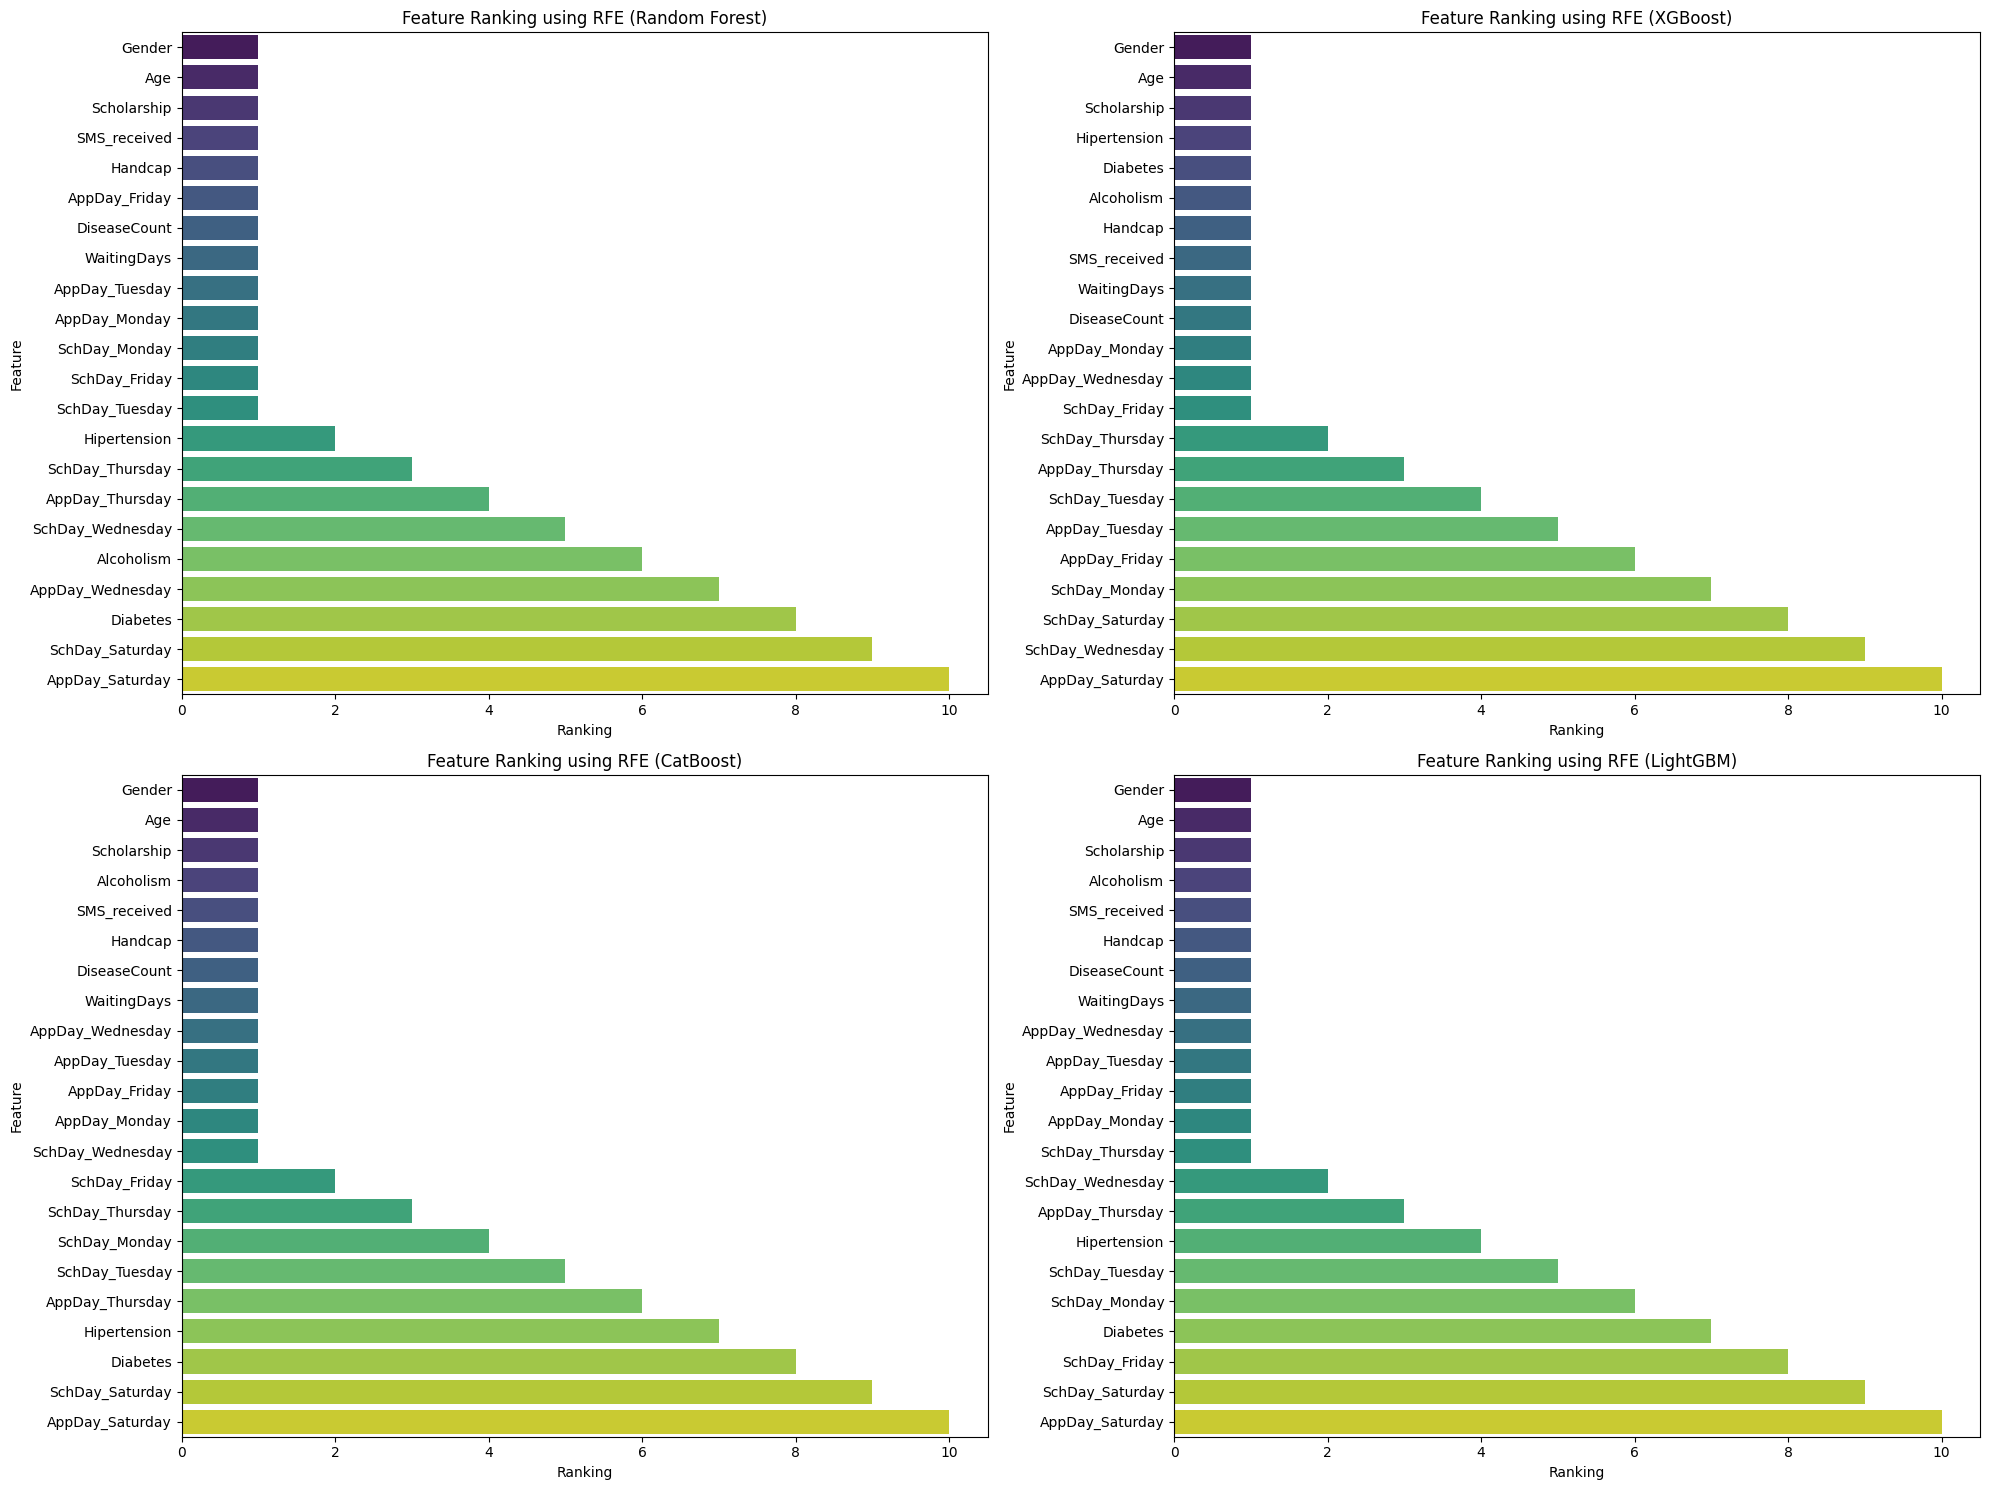

In [74]:
plt.figure(figsize=(20, 15))

# Core Loop: Execute RFE, store selected features, and retrain each model
for index, (name, estimator) in enumerate(rfe_estimators.items()):
    print(f"\n" + "="*60)
    print(f"Running RFE & Feature Selection for {name}...")
    print("="*60)
    
    rfe = RFE(estimator=estimator, n_features_to_select=13)
    
    # Handle CatBoost class weights during fit to avoid cloning error
    if name == "CatBoost":
        rfe.fit(X_train, y_train, sample_weight=sample_weights)
    else:
        rfe.fit(X_train, y_train)
        
    current_selected_features = X_train.columns[rfe.support_]
    rfe_selected_features_dict[name] = current_selected_features
    print(f"Selected Features for {name}:")
    print(list(current_selected_features))
    
    X_train_rfe = X_train[current_selected_features]
    
    if name == "CatBoost":
        estimator.fit(X_train_rfe, y_train, sample_weight=sample_weights)
    else:
        estimator.fit(X_train_rfe, y_train)
        
    rfe_final_models[name] = estimator
    
    # Generate and plot the feature ranking results
    rfe_results = pd.DataFrame({
        "Feature": X_train.columns,
        "Ranking": rfe.ranking_
    }).sort_values("Ranking")
    
    plt.subplot(2, 2, index + 1)
    sns.barplot(data=rfe_results, x="Ranking", y="Feature", palette="viridis")
    plt.title(f"Feature Ranking using RFE ({name})")

plt.tight_layout()
plt.show()

Model Training and Evaluation after Feature Selection


Random Forest after RFE Feature Selection (Balanced)
Training Accuracy : 0.6022
Testing Accuracy  : 0.5818

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.52      0.67     17642
           1       0.30      0.82      0.44      4463

    accuracy                           0.58     22105
   macro avg       0.61      0.67      0.55     22105
weighted avg       0.80      0.58      0.62     22105


XGBoost after RFE Feature Selection (Balanced)
Training Accuracy : 0.5916
Testing Accuracy  : 0.5821

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.52      0.67     17642
           1       0.30      0.83      0.44      4463

    accuracy                           0.58     22105
   macro avg       0.61      0.67      0.55     22105
weighted avg       0.80      0.58      0.62     22105


CatBoost after RFE Feature Selection (Balanced)
Training Accuracy : 0.5934
Testing Accu

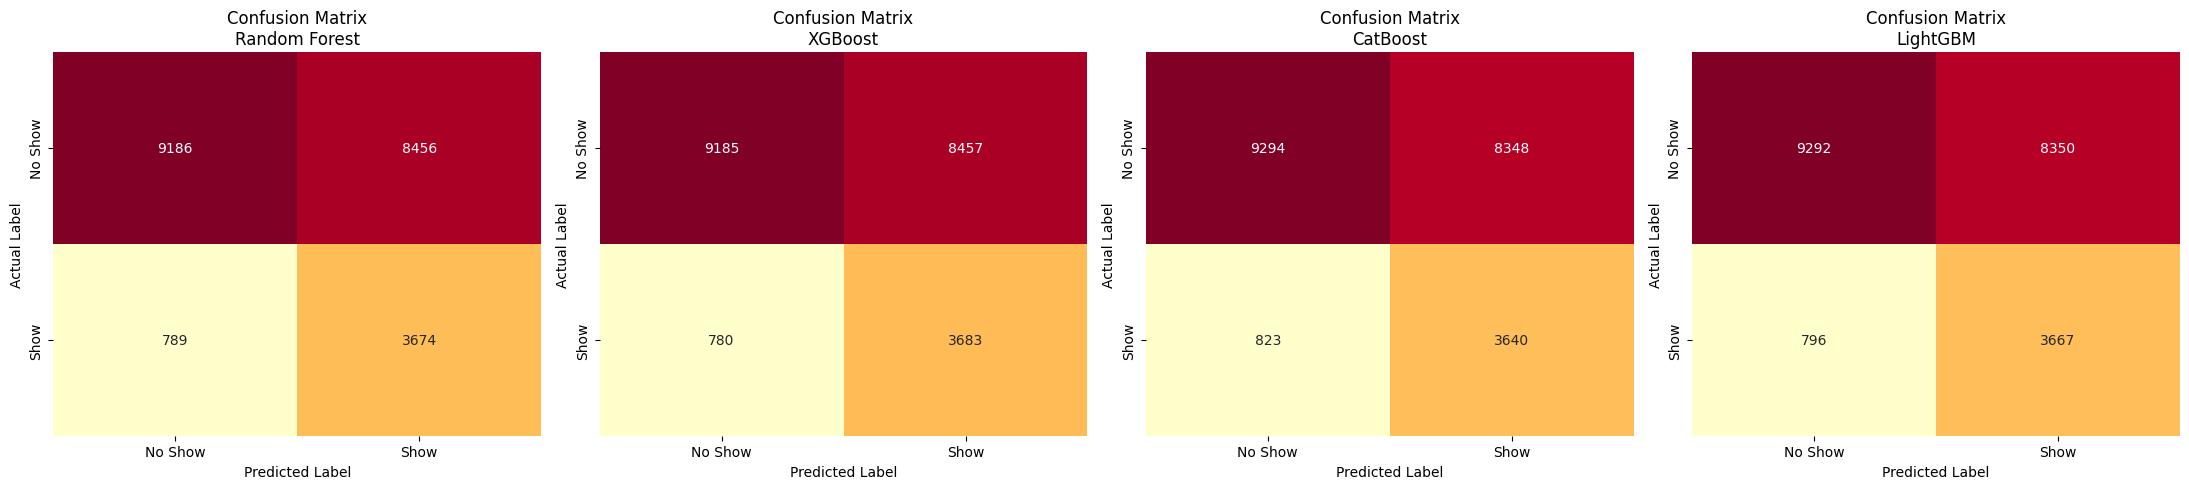

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.581769,0.302885,0.823213,0.442837
1,XGBoost,0.582131,0.303377,0.825230,0.443655
2,CatBoost,0.585116,0.303637,0.815595,0.442526
3,LightGBM,0.586247,0.305151,0.821645,0.445024


In [75]:
results_rfe_final = evaluate_models(
    models=rfe_final_models,
    x_train_full=X_train,
    x_test_full=X_test,
    y_train=y_train,
    y_test=y_test,
    title="after RFE Feature Selection (Balanced)",
    cmap="YlOrRd",
    features_dict=rfe_selected_features_dict # Passed dict to safely evaluate dynamic columns
)

results_rfe_final

Save Production Model (LightGBM + RFE)

In [76]:
best_model_name = "LightGBM"
lgbm_rfe_model = rfe_final_models[best_model_name]
lgbm_selected_features = rfe_selected_features_dict[best_model_name]

# Serialize and dump the final model file
joblib.dump(lgbm_rfe_model, 'lgbm_rfe_model.pkl')
print('Model saved successfully as lgbm_rfe_model.pkl')

Model saved successfully as lgbm_rfe_model.pkl


Testing Inference on Single Sample

In [77]:
X_test_rfe_final = X_test[lgbm_selected_features]
sample = X_test_rfe_final.iloc[[0]]

print("\nSample Features for Prediction:")
print(sample)

prediction = lgbm_rfe_model.predict(sample)[0]
probabilities = lgbm_rfe_model.predict_proba(sample)[0]

print("\n" + "-"*30)
print("Prediction Results:")
print("-"*30)
print("Prediction  :", prediction)
print("Probability :", probabilities)
print("Actual      :", y_test.iloc[0])
print("-"*30)


Sample Features for Prediction:
       Gender  Age  Scholarship  Alcoholism  Handcap  SMS_received  \
82811       0   53            0           0        0             1   

       WaitingDays  DiseaseCount  AppDay_Friday  AppDay_Monday  \
82811           18             0              0              1   

       AppDay_Tuesday  AppDay_Wednesday  SchDay_Thursday  
82811               0                 0                1  

------------------------------
Prediction Results:
------------------------------
Prediction  : 1
Probability : [0.45360528 0.54639472]
Actual      : 1
------------------------------
